In [1]:
import supervision as sv


In [2]:
from rfdetr import RFDETRNano
# from rfdetr import RFDETRMedium
# from rfdetr import RFDETRLarge
model = RFDETRNano()
# model = RFDETRMedium()
# model = RFDETRLarge()

Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
Loading pretrain weights


In [3]:
print("test")

test


In [ ]:
model.train(
    dataset_dir="rfdetr_dataset", 
    epochs=100, 
    batch_size=8, 
    grad_accum_steps=2, 
    gradient_checkpointing=False,
    resolution=448,
    lr=0.0001,
    dropout=0.15,
    device="cuda", 
    save_dir="rfdetr_weights",
    tensorboard=True, 
    output_dir="output_small_2",
    weight_decay=1e-4,
    use_ema=True,
    early_stopping=True,
    early_stopping_patience=10,
    early_stopping_min_delta=0.001,
    early_stopping_use_ema=True
)

TensorBoard logging initialized. To monitor logs, use 'tensorboard --logdir output_small_2' and open http://localhost:6006/ in browser.
Not using distributed mode
git:
  sha: c87f1e318763d77097bee9eb54e7dfe400c81b09, status: has uncommited changes, branch: main

Namespace(num_classes=12, grad_accum_steps=2, amp=True, lr=0.0001, lr_encoder=0.00015, batch_size=8, weight_decay=0.0001, epochs=100, lr_drop=100, clip_max_norm=0.1, lr_vit_layer_decay=0.8, lr_component_decay=0.7, do_benchmark=False, dropout=0.15, drop_path=0.0, drop_mode='standard', drop_schedule='constant', cutoff_epoch=0, pretrained_encoder=None, pretrain_weights='rf-detr-nano.pth', pretrain_exclude_keys=None, pretrain_keys_modify_to_load=None, pretrained_distiller=None, encoder='dinov2_windowed_small', vit_encoder_num_layers=12, window_block_indexes=None, position_embedding='sine', out_feature_indexes=[3, 6, 9, 12], freeze_encoder=False, layer_norm=True, rms_norm=False, backbone_lora=False, force_no_pretrain=False, dec_laye

Epoch: [0]  [  0/656]  eta: 0:19:25  lr: 0.000100  class_error: 93.22  loss: 7.4761 (7.4761)  loss_ce: 1.3791 (1.3791)  loss_bbox: 0.1971 (0.1971)  loss_giou: 0.8991 (0.8991)  loss_ce_0: 1.3647 (1.3647)  loss_bbox_0: 0.1715 (0.1715)  loss_giou_0: 0.8283 (0.8283)  loss_ce_enc: 1.7478 (1.7478)  loss_bbox_enc: 0.1467 (0.1467)  loss_giou_enc: 0.7418 (0.7418)  loss_ce_unscaled: 1.3791 (1.3791)  class_error_unscaled: 93.2203 (93.2203)  loss_bbox_unscaled: 0.0394 (0.0394)  loss_giou_unscaled: 0.4496 (0.4496)  cardinality_error_unscaled: 3844.2500 (3844.2500)  loss_ce_0_unscaled: 1.3647 (1.3647)  loss_bbox_0_unscaled: 0.0343 (0.0343)  loss_giou_0_unscaled: 0.4141 (0.4141)  cardinality_error_0_unscaled: 3808.7500 (3808.7500)  loss_ce_enc_unscaled: 1.7478 (1.7478)  loss_bbox_enc_unscaled: 0.0293 (0.0293)  loss_giou_enc_unscaled: 0.3709 (0.3709)  cardinality_error_enc_unscaled: 3875.1250 (3875.1250)  time: 1.7765  data: 0.4618  max mem: 4319
Epoch: [0]  [ 10/656]  eta: 0:07:37  lr: 0.000100  clas

Test:  [  0/282]  eta: 0:01:33  class_error: 16.36  loss: 4.3961 (4.3961)  loss_ce: 0.8281 (0.8281)  loss_bbox: 0.0868 (0.0868)  loss_giou: 0.5514 (0.5514)  loss_ce_0: 0.8281 (0.8281)  loss_bbox_0: 0.0854 (0.0854)  loss_giou_0: 0.5454 (0.5454)  loss_ce_enc: 0.8125 (0.8125)  loss_bbox_enc: 0.0909 (0.0909)  loss_giou_enc: 0.5675 (0.5675)  loss_ce_unscaled: 0.8281 (0.8281)  class_error_unscaled: 16.3636 (16.3636)  loss_bbox_unscaled: 0.0174 (0.0174)  loss_giou_unscaled: 0.2757 (0.2757)  cardinality_error_unscaled: 288.5000 (288.5000)  loss_ce_0_unscaled: 0.8281 (0.8281)  loss_bbox_0_unscaled: 0.0171 (0.0171)  loss_giou_0_unscaled: 0.2727 (0.2727)  cardinality_error_0_unscaled: 286.0000 (286.0000)  loss_ce_enc_unscaled: 0.8125 (0.8125)  loss_bbox_enc_unscaled: 0.0182 (0.0182)  loss_giou_enc_unscaled: 0.2837 (0.2837)  cardinality_error_enc_unscaled: 273.6250 (273.6250)  time: 0.3318  data: 0.2259  max mem: 5761
Test:  [ 10/282]  eta: 0:00:47  class_error: 2.22  loss: 4.1342 (4.1808)  loss_c

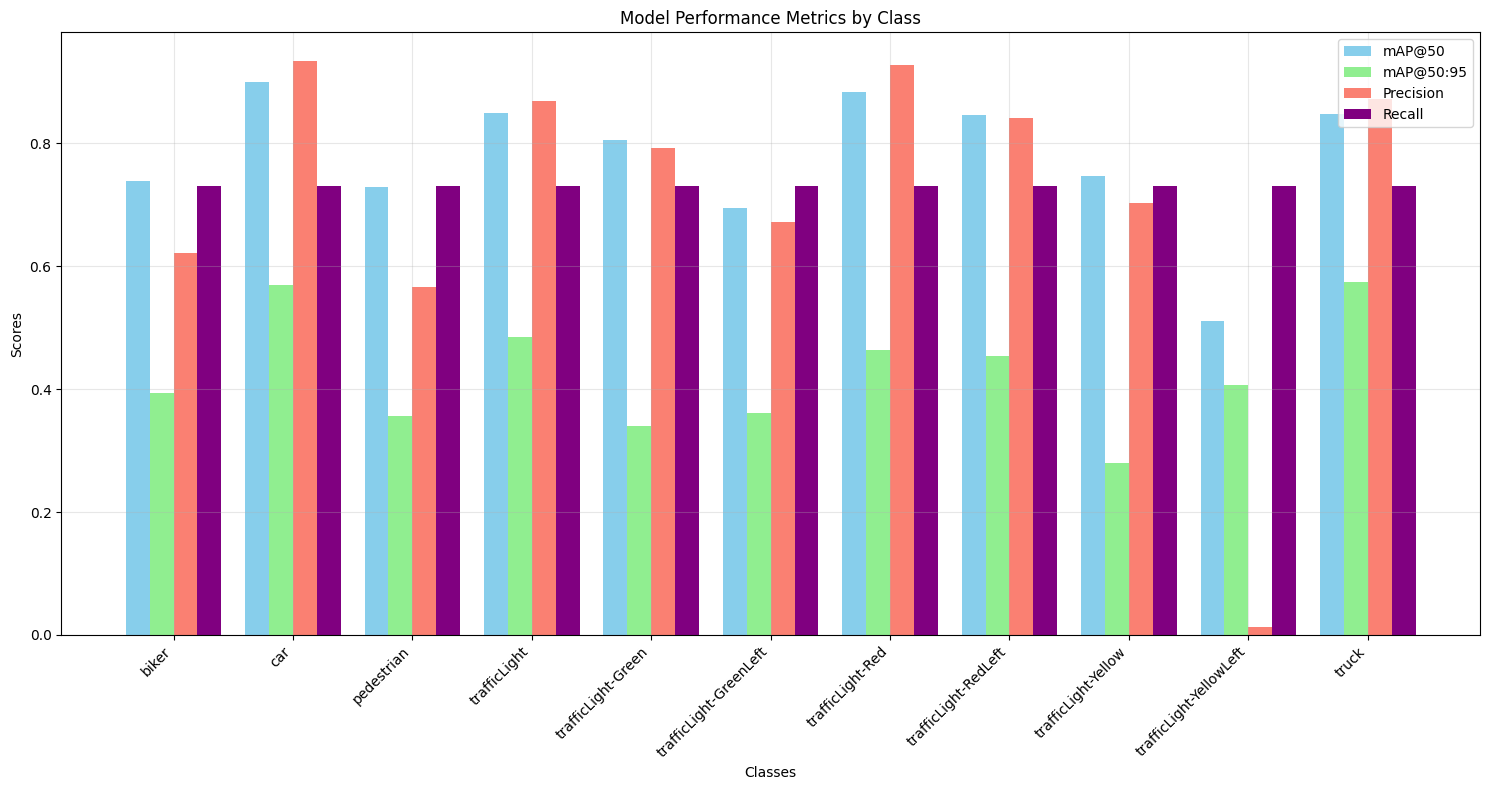

In [9]:
import json
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load the results
with open('output/results.json', 'r') as f:
    results = json.load(f)

# Extract validation results
valid_results = results['class_map']['valid']

# Create a DataFrame
data = []
for item in valid_results:
    if item['class'] != 'all':  # Exclude the 'all' summary row
        data.append({
            'class': item['class'],
            'mAP@50': item['map@50'],
            'mAP@50:95': item['map@50:95'],
            'Precision': item['precision'],
            'Recall': item['recall']
        })

df = pd.DataFrame(data)

# Create the visualization
plt.figure(figsize=(15, 8))
x = range(len(df['class']))

# Plot bars
width = 0.2
plt.bar(x, df['mAP@50'], width, label='mAP@50', color='skyblue')
plt.bar([i + width for i in x], df['mAP@50:95'], width, label='mAP@50:95', color='lightgreen')
plt.bar([i + width * 2 for i in x], df['Precision'], width, label='Precision', color='salmon')
plt.bar([i + width * 3 for i in x], df['Recall'], width, label='Recall', color='purple')

# Customize the plot
plt.xlabel('Classes')
plt.ylabel('Scores')
plt.title('Model Performance Metrics by Class')
plt.xticks([i + width * 1.5 for i in x], df['class'], rotation=45, ha='right')
plt.legend(loc='upper right')
plt.grid(True, alpha=0.3)

# Adjust layout to prevent label cutoff
plt.tight_layout()
plt.show()

In [11]:
from PIL import Image
import supervision as sv

image = Image.open("./rfdetr_dataset/valid/1478020224197266285.jpg")
detections = model.predict(image)

val_ds = sv.DetectionDataset.from_coco(
    images_directory_path="rfdetr_dataset/valid",
    annotations_path="rfdetr_dataset/valid/_annotations.coco.json"
)

In [12]:
import supervision as sv
from tqdm import tqdm
from supervision.metrics import MeanAveragePrecision

targets = []
predictions = []

for path, image, annotations in tqdm(val_ds):
    image = Image.open(path)
    detections = model.predict(image, threshold=0)

    targets.append(annotations)
    predictions.append(detections)

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 2250/2250 [02:10<00:00, 17.24it/s]


In [13]:
map_metric = MeanAveragePrecision()
map_result = map_metric.update(predictions, targets).compute()
print(map_result)

Average Precision (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.471
Average Precision (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.877
Average Precision (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.446
Average Precision (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.429
Average Precision (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ]                 = 0.623
Average Precision (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ]                 = 0.753


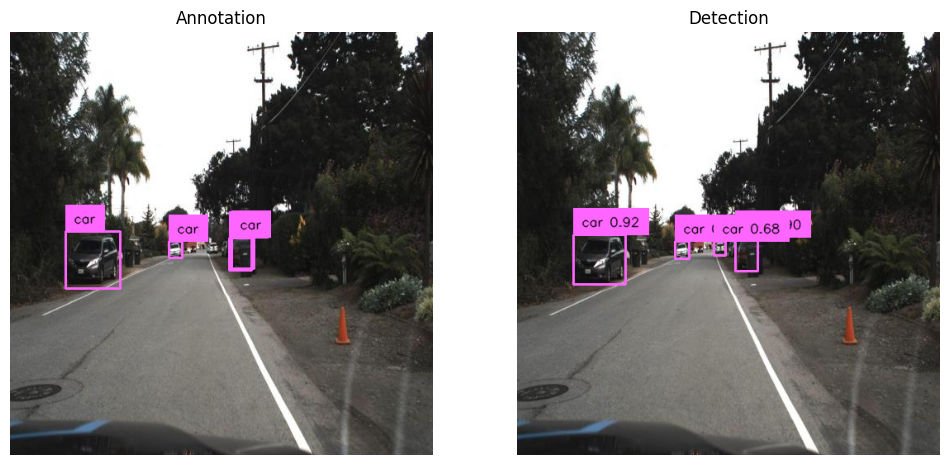

In [17]:
import supervision as sv
from PIL import Image

path, image, annotations = val_ds[15]
image = Image.open(path)

detections = model.predict(image, threshold=0.5)

text_scale = sv.calculate_optimal_text_scale(resolution_wh=image.size)
thickness = sv.calculate_optimal_line_thickness(resolution_wh=image.size)
color = sv.ColorPalette.from_hex([
    "#ffff00", "#ff9b00", "#ff66ff", "#3399ff", "#ff66b2", "#ff8080",
    "#b266ff", "#9999ff", "#66ffff", "#33ff99", "#66ff66", "#99ff00"
])

bbox_annotator = sv.BoxAnnotator(color=color,thickness=thickness)
label_annotator = sv.LabelAnnotator(
    color=color,
    text_color=sv.Color.BLACK,
    text_scale=text_scale)

annotations_labels = [
    f"{val_ds.classes[class_id]}"
    for class_id
    in annotations.class_id
]

detections_labels = [
    f"{val_ds.classes[class_id]} {confidence:.2f}"
    for class_id, confidence
    in zip(detections.class_id, detections.confidence)
]

annotation_image = image.copy()
annotation_image = bbox_annotator.annotate(annotation_image, annotations)
annotation_image = label_annotator.annotate(annotation_image, annotations, annotations_labels)

detections_image = image.copy()
detections_image = bbox_annotator.annotate(detections_image, detections)
detections_image = label_annotator.annotate(detections_image, detections, detections_labels)

sv.plot_images_grid(images=[annotation_image, detections_image], grid_size=(1, 2), titles=["Annotation", "Detection"])